<a href="https://colab.research.google.com/github/Inc-pixel/Metal-Subgenres/blob/main/Stage3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
from itertools import combinations
%pip install seaborn
!mamba install pandas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, integrate
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests

os.makedirs("figures", exist_ok=True)   # folder for saved charts
pd.set_option("display.width", 160)     # wider printed tables

mambajs 0.21.4

Process pip requirements ...

Requirement seaborn already satisfied.
mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
error sending request
Solving environment...
Solving took 1.958 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.0.6    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.4   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge


In [ ]:
GENRES = ["metalcore", "death-metal", "black-metal", "heavy-metal", "grindcore"]
FEATURES = ["energy", "loudness", "valence", "danceability", "tempo", "instrumentalness"]


In [ ]:
metal = pd.read_csv("metal_clean.csv")
print(metal["track_genre"].value_counts())
metal.groupby("track_genre")[FEATURES].agg(["mean", "std"]).round(2)

track_genre
black-metal    822
grindcore      675
death-metal    659
metalcore      616
heavy-metal    479
Name: count, dtype: int64


energy       loudness       valence       danceability        \
              mean   std     mean   std    mean   std         mean   std   
track_genre                                                                
black-metal   0.87  0.17    -6.74  2.88    0.19  0.15         0.29  0.13   
death-metal   0.93  0.09    -5.51  2.25    0.26  0.16         0.36  0.12   
grindcore     0.93  0.10    -5.99  2.74    0.22  0.18         0.27  0.09   
heavy-metal   0.88  0.13    -5.52  2.41    0.38  0.17         0.44  0.11   
metalcore     0.91  0.10    -4.50  1.64    0.33  0.16         0.43  0.11   

              tempo        instrumentalness        
               mean    std             mean   std  
track_genre                                        
black-metal  128.78  30.31             0.45  0.37  
death-metal  123.73  29.27             0.31  0.34  
grindcore    119.60  26.34             0.55  0.36  
heavy-metal  125.55  26.44             0.08  0.20  
metalcore    130.85  31.79             0.04  0.14

In [ ]:
pd.crosstab(metal["track_genre"], metal["mode"], normalize="index").round(2)

mode,0,1
track_genre,,
black-metal,0.41,0.59
death-metal,0.39,0.61
grindcore,0.36,0.64
heavy-metal,0.46,0.54
metalcore,0.48,0.52


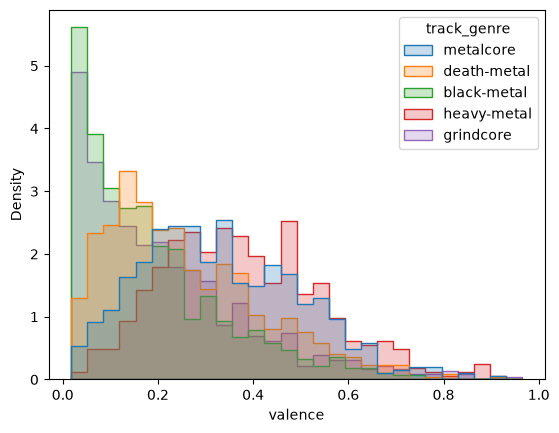

In [ ]:
sns.histplot(data=metal, x="valence", hue="track_genre", hue_order=GENRES,
element="step", stat="density", common_norm=False)

plt.show()

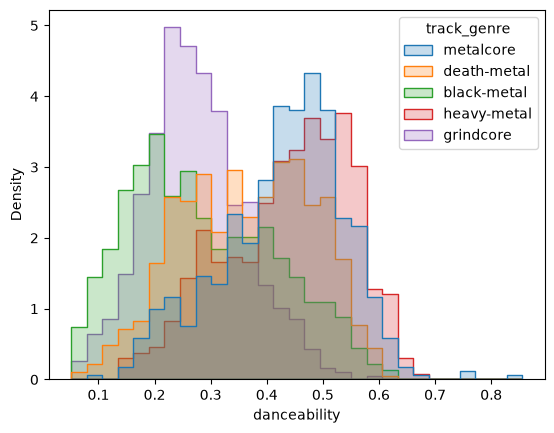

In [ ]:
sns.histplot(data=metal, x="danceability", hue="track_genre", hue_order=GENRES,
element="step", stat="density", common_norm=False)

plt.show()

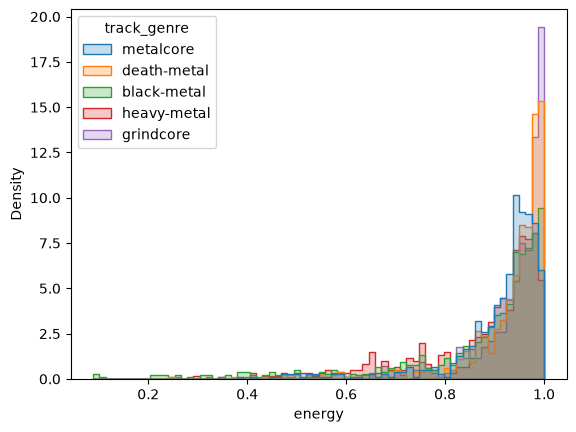

In [ ]:
sns.histplot(data=metal, x="energy", hue="track_genre", hue_order=GENRES,
element="step", stat="density", common_norm=False)

plt.show()

In [ ]:
ALPHA = 0.05
ALPHA_PER_FEATURE = ALPHA / len(FEATURES) # Bonferroni: 0.05 / 6
def eta_squared(groups):
    """Share of total variation explained by subgenre: SS_between / SS_total."""
    all_values = np.concatenate(groups)
    grand_mean = all_values.mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
    ss_total = ((all_values - grand_mean) ** 2).sum()
    return ss_between / ss_total